# Black-Scholes option pricing: a walk-through

This notebook uses `black_scholes.py` to price European options, plot their Greeks and recover implied volatility.
Every cell runs offline with illustrative parameters; the last section shows how to use live market data.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import black_scholes as bs

plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.grid": True,
                     "grid.color": "#e4e3df", "axes.spines.top": False, "axes.spines.right": False})
CALL, PUT = "#2a78d6", "#eb6834"

# An at-the-money option on a 100 stock, 3 months to expiry, 4% rate, 25% volatility
S, K, T, r, sigma = 100.0, 100.0, 0.25, 0.04, 0.25

## 1. Prices and put-call parity

In [2]:
call = bs.price(S, K, T, r, sigma, "call")
put = bs.price(S, K, T, r, sigma, "put")
print(f"Call {call:.4f}   Put {put:.4f}")
print(f"Put-call parity: C - P = {call - put:.4f}, S - K*exp(-rT) = {S - K * np.exp(-r * T):.4f}")

Call 5.4721   Put 4.4771
Put-call parity: C - P = 0.9950, S - K*exp(-rT) = 0.9950


## 2. How the price depends on the spot and on time to expiry

With more time left the option is worth more, and its value curve is smoother; close to expiry it approaches the payoff (the kink at the strike).

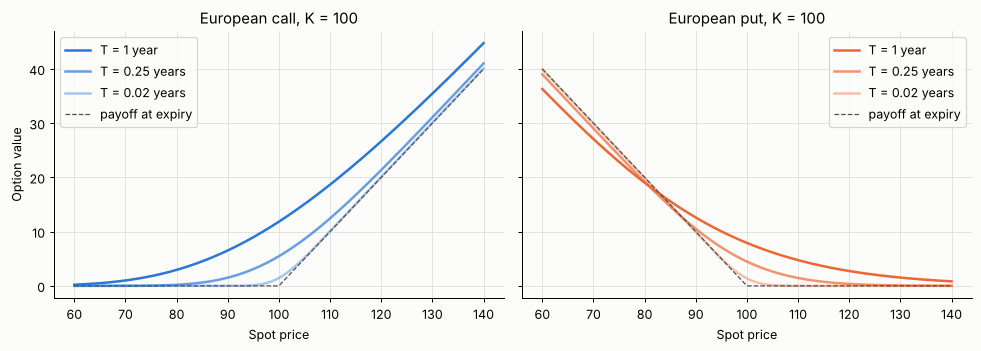

In [3]:
spots = np.linspace(60, 140, 200)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, kind, colour in [(axes[0], "call", CALL), (axes[1], "put", PUT)]:
    for T_i, alpha in [(1.0, 1.0), (0.25, 0.7), (0.02, 0.4)]:
        ax.plot(spots, bs.price(spots, K, T_i, r, sigma, kind), color=colour, alpha=alpha, lw=2,
                label=f"T = {T_i:g} year" + ("" if T_i == 1 else "s"))
    payoff = np.maximum(spots - K, 0) if kind == "call" else np.maximum(K - spots, 0)
    ax.plot(spots, payoff, color="#52514e", ls="--", lw=1, label="payoff at expiry")
    ax.set_title(f"European {kind}, K = {K:g}")
    ax.set_xlabel("Spot price")
    ax.legend()
axes[0].set_ylabel("Option value")
fig.tight_layout()

## 3. The Greeks

Delta is the hedge ratio, gamma how fast delta changes, vega the exposure to volatility and theta the daily time decay.
Gamma and vega are the same for calls and puts and peak near the strike.

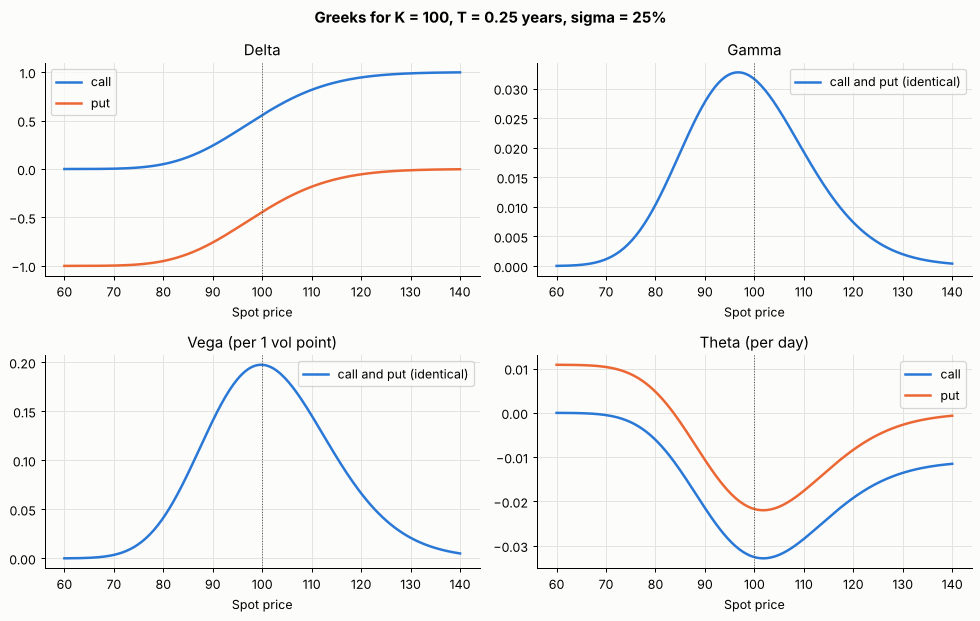

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
panels = [
    ("Delta", lambda k: bs.delta(spots, K, T, r, sigma, k)),
    ("Gamma", lambda k: bs.gamma(spots, K, T, r, sigma)),
    ("Vega (per 1 vol point)", lambda k: bs.vega(spots, K, T, r, sigma) / 100),
    ("Theta (per day)", lambda k: bs.theta(spots, K, T, r, sigma, k) / 365),
]
for ax, (name, f) in zip(axes.flat, panels):
    both = name.startswith(("Delta", "Theta"))
    ax.plot(spots, f("call"), color=CALL, lw=2, label="call" if both else "call and put (identical)")
    if both:
        ax.plot(spots, f("put"), color=PUT, lw=2, label="put")
    ax.axvline(K, color="#52514e", lw=0.8, ls=":")
    ax.set_title(name)
    ax.set_xlabel("Spot price")
    ax.legend()
fig.suptitle(f"Greeks for K = {K:g}, T = {T:g} years, sigma = {sigma:.0%}", fontweight="bold")
fig.tight_layout()

In [5]:
for kind in ("call", "put"):
    print(kind, {name: round(value, 4) for name, value in bs.greeks(S, K, T, r, sigma, kind).items()})

call {'price': 5.4721, 'delta': 0.5567, 'gamma': 0.0316, 'vega_per_vol_point': 0.1975, 'theta_per_day': -0.0325, 'rho_per_rate_point': 0.1255}
put {'price': 4.4771, 'delta': -0.4433, 'gamma': 0.0316, 'vega_per_vol_point': 0.1975, 'theta_per_day': -0.0217, 'rho_per_rate_point': -0.122}


## 4. Implied volatility

Given a market price, find the volatility that makes the model price equal to it. The solver uses Brent's method,
which always converges inside its search range, and refuses prices that break the no-arbitrage bounds.

In [6]:
market_price = 6.50
iv = bs.implied_volatility(market_price, S, K, T, r, "call")
print(f"A call trading at {market_price:.2f} implies a volatility of {iv:.2%}")
print(f"Check: model price at that volatility = {bs.price(S, K, T, r, iv, 'call'):.4f}")

try:
    bs.implied_volatility(120.0, S, K, T, r, "call")
except ValueError as error:
    print("Impossible price rejected:", error)

A call trading at 6.50 implies a volatility of 30.21%
Check: model price at that volatility = 6.5000
Impossible price rejected: Price 120.0000 is outside the no-arbitrage range (0.9950, 100.0000); no implied volatility exists.


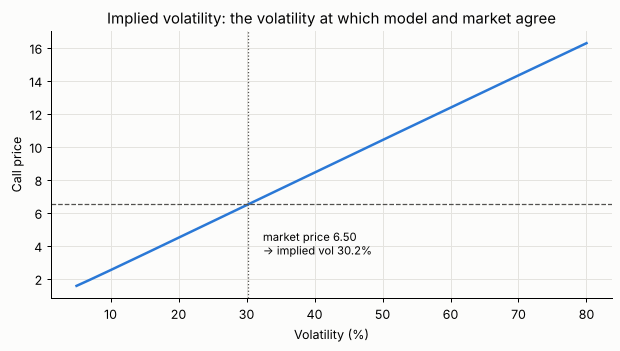

In [7]:
vols = np.linspace(0.05, 0.80, 200)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(vols * 100, bs.price(S, K, T, r, vols, "call"), color=CALL, lw=2)
ax.axhline(market_price, color="#52514e", ls="--", lw=1)
ax.axvline(iv * 100, color="#52514e", ls=":", lw=1)
ax.annotate(f"market price {market_price:.2f}\n-> implied vol {iv:.1%}", (iv * 100, market_price),
            xytext=(12, -40), textcoords="offset points", fontsize=9)
ax.set_xlabel("Volatility (%)")
ax.set_ylabel("Call price")
ax.set_title("Implied volatility: the volatility at which model and market agree")
fig.tight_layout()

## 5. American options: a binomial tree

Black-Scholes only prices European options. A Cox-Ross-Rubinstein tree can also price American options by checking,
at every node, whether exercising immediately is worth more than holding. For a European option the tree converges to
the Black-Scholes price as the number of steps grows (with the characteristic odd/even oscillation).

300-step tree: European put 4.4729, American put 4.5535, Black-Scholes 4.4771


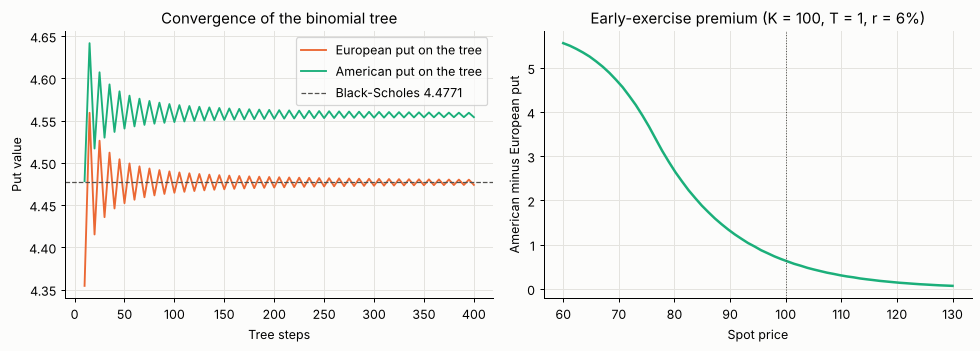

In [8]:
import binomial

steps_grid = np.arange(10, 401, 5)
european = [binomial.crr_price(S, K, T, r, sigma, "put", steps=n) for n in steps_grid]
american = [binomial.crr_price(S, K, T, r, sigma, "put", steps=n, american=True) for n in steps_grid]
bs_put = bs.price(S, K, T, r, sigma, "put")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(steps_grid, european, color=PUT, lw=1.5, label="European put on the tree")
axes[0].plot(steps_grid, american, color="#1baf7a", lw=1.5, label="American put on the tree")
axes[0].axhline(bs_put, color="#52514e", ls="--", lw=1, label=f"Black-Scholes {bs_put:.4f}")
axes[0].set_xlabel("Tree steps")
axes[0].set_ylabel("Put value")
axes[0].set_title("Convergence of the binomial tree")
axes[0].legend()

spot_grid = np.linspace(60, 130, 60)
premium = [binomial.early_exercise_premium(s, K, 1.0, 0.06, sigma, "put", steps=300) for s in spot_grid]
axes[1].plot(spot_grid, premium, color="#1baf7a", lw=2)
axes[1].axvline(K, color="#52514e", ls=":", lw=0.8)
axes[1].set_xlabel("Spot price")
axes[1].set_ylabel("American minus European put")
axes[1].set_title("Early-exercise premium (K = 100, T = 1, r = 6%)")
fig.tight_layout()
print(f"300-step tree: European put {binomial.crr_price(S, K, T, r, sigma, 'put', steps=300):.4f}, "
      f"American put {binomial.crr_price(S, K, T, r, sigma, 'put', steps=300, american=True):.4f}, "
      f"Black-Scholes {bs_put:.4f}")

## 6. Monte Carlo and variance reduction

Monte Carlo averages discounted payoffs over simulated prices. Its error shrinks only with the square root of the
number of paths, so variance reduction matters: antithetic draws pair each shock with its mirror image, and a control
variate corrects the estimate using the stock price, whose expected value is known exactly.

In [9]:
import monte_carlo as mc

exact = bs.price(S, K, T, r, sigma, "call")
methods = {"plain": {}, "antithetic": {"antithetic": True}, "control variate": {"control_variate": True},
           "both": {"antithetic": True, "control_variate": True}}
for name, options in methods.items():
    result = mc.mc_price(S, K, T, r, sigma, "call", paths=100_000, seed=1, **options)
    print(f"{name:<16} {result.price:.4f}  std error {result.std_error:.4f}  (exact {exact:.4f})")

plain            5.4192  std error 0.0258  (exact 5.4721)
antithetic       5.4434  std error 0.0192  (exact 5.4721)
control variate  5.4554  std error 0.0117  (exact 5.4721)
both             5.4688  std error 0.0059  (exact 5.4721)


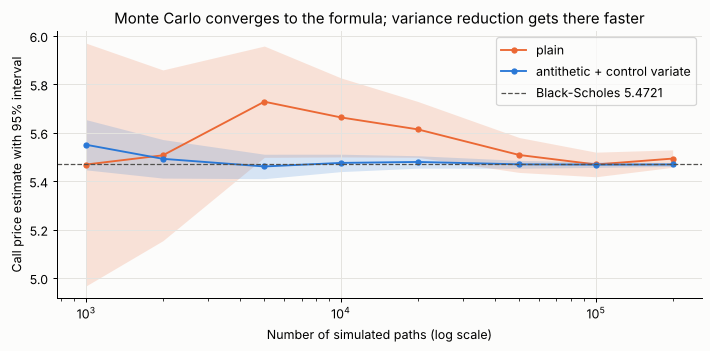

In [10]:
path_grid = np.array([1_000, 2_000, 5_000, 10_000, 20_000, 50_000, 100_000, 200_000])
fig, ax = plt.subplots(figsize=(8, 4))
for name, colour, options in [("plain", PUT, {}), ("antithetic + control variate", CALL,
                                                   {"antithetic": True, "control_variate": True})]:
    results = [mc.mc_price(S, K, T, r, sigma, "call", paths=n, seed=5, **options) for n in path_grid]
    prices = np.array([res.price for res in results]); errors = np.array([res.std_error for res in results])
    ax.fill_between(path_grid, prices - 1.96 * errors, prices + 1.96 * errors, color=colour, alpha=0.18, lw=0)
    ax.plot(path_grid, prices, "o-", color=colour, ms=4, lw=1.5, label=name)
ax.axhline(exact, color="#52514e", ls="--", lw=1, label=f"Black-Scholes {exact:.4f}")
ax.set_xscale("log")
ax.set_xlabel("Number of simulated paths (log scale)")
ax.set_ylabel("Call price estimate with 95% interval")
ax.set_title("Monte Carlo converges to the formula; variance reduction gets there faster")
ax.legend()
fig.tight_layout()

## 7. Delta hedging: where an options desk's P&L comes from

Sell an option at a price based on the implied volatility, hold delta shares, rebalance at fixed intervals, while the
stock moves with its realised volatility. Two results: the hedging error shrinks roughly with the square root of the
number of rebalances, and selling volatility above what the stock then realises makes money on average.

Mean P&L selling 10 points rich: 1.99 (vega x 0.10 = 1.97)


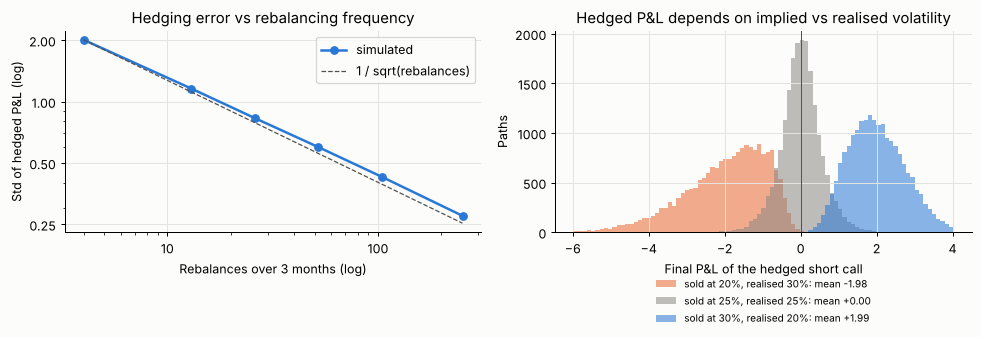

In [11]:
import hedging

rebalances = np.array([4, 13, 26, 52, 104, 252])
spread = [hedging.delta_hedge_pnl(S, K, T, r, 0.25, 0.25, "call", steps=n, paths=20_000, seed=2).std()
          for n in rebalances]

fair = hedging.delta_hedge_pnl(S, K, T, r, 0.25, 0.25, "call", steps=63, paths=20_000, seed=3)
rich = hedging.delta_hedge_pnl(S, K, T, r, 0.30, 0.20, "call", steps=63, paths=20_000, seed=3)
cheap = hedging.delta_hedge_pnl(S, K, T, r, 0.20, 0.30, "call", steps=63, paths=20_000, seed=3)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].loglog(rebalances, spread, "o-", color=CALL, lw=2, label="simulated")
axes[0].loglog(rebalances, spread[0] * np.sqrt(rebalances[0] / rebalances), "--", color="#52514e", lw=1,
               label="1 / sqrt(rebalances)")
from matplotlib.ticker import ScalarFormatter, NullFormatter
for axis in (axes[0].xaxis, axes[0].yaxis):
    axis.set_major_formatter(ScalarFormatter()); axis.set_minor_formatter(NullFormatter())
axes[0].set_yticks([0.25, 0.5, 1, 2])
axes[0].set_xlabel("Rebalances over 3 months (log)")
axes[0].set_ylabel("Std of hedged P&L (log)")
axes[0].set_title("Hedging error vs rebalancing frequency")
axes[0].legend()

everything = np.concatenate([cheap, fair, rich])
bins = np.linspace(np.percentile(everything, 0.1), np.percentile(everything, 99.9), 90)
for pnl, colour, label in [(cheap, PUT, "sold at 20%, realised 30%"), (fair, "#8a8984", "sold at 25%, realised 25%"),
                           (rich, CALL, "sold at 30%, realised 20%")]:
    axes[1].hist(pnl, bins=bins, color=colour, alpha=0.55, label=f"{label}: mean {pnl.mean():+.2f}")
axes[1].axvline(0, color="#52514e", lw=0.8)
axes[1].set_xlabel("Final P&L of the hedged short call")
axes[1].set_ylabel("Paths")
axes[1].set_title("Hedged P&L depends on implied vs realised volatility")
axes[1].legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=1, frameon=False)
fig.tight_layout()
vega_estimate = bs.vega(S, K, T, r, 0.25) * 0.10
print(f"Mean P&L selling 10 points rich: {rich.mean():.2f} (vega x 0.10 = {vega_estimate:.2f})")

## 8. Live data (needs internet)

`price_option.py` downloads a year of prices and an at-the-money option quote with yfinance, then compares the
**implied** volatility with the **historical** one:

```bash
pip install yfinance
python price_option.py AAPL   # implied vs historical volatility for an at-the-money option
python vol_smile.py SPY       # implied volatility across strikes, saved as smile_SPY.png
```

A model price that differs from the market price does not mean the option is cheap or expensive. It means the market
expects a different volatility from the one measured in the past, which is the comparison the script reports.